# Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)

### 1. Aim
To sort three large arrays using Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Generate three independent arrays containing random integers.<br>2. Perform multi-pass sorting and reversing.<br>3. Sequential: sort Array 1 -> Array 2 -> Array 3.<br>4. Pool: distribute across 3 workers in `mp.Pool(3)`.<br>5. Process: sort concurrently using 3 `mp.Process` instances.<br>6. Thread: sort concurrently using 3 `threading.Thread` workers.<br>7. Verify sorted results and plot execution-time and speedup graphs.

### 3. Python Implementation


In [1]:
"""
Practical 8: Bubble Sort on Three Different Arrays (Pattern 2)
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def bubble_sort_task(task):
    size, iters, seed = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 10_000_000, size=size)
    for _ in range(iters):
        arr = np.sort(arr)
        arr = arr[::-1].copy()
    return arr[:5].tolist()

def proc_worker(task, q):
    q.put(bubble_sort_task(task))

def thread_worker(task, results, idx):
    results[idx] = bubble_sort_task(task)

def main():
    print("=" * 60)
    print("Practical 8: Bubble Sort on Three Different Arrays")
    print("=" * 60)
    SIZE = 2_000_000
    ITERS = 10
    tasks = [(SIZE, ITERS, 101), (SIZE, ITERS, 202), (SIZE, ITERS, 303)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = bubble_sort_task(tasks[0])
    r2 = bubble_sort_task(tasks[1])
    r3 = bubble_sort_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        pool_res = pool.map(bubble_sort_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Sorted 3 arrays of {SIZE:,} elements each across {ITERS} passes.")
    print(f"Sample sorted first 5: {seq_res[0]}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Array Sorting)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("08_bubble_sort_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    plt.plot(methods, speedups, marker='o', linewidth=2.5, markersize=8, color='#2980b9', label='Speedup')
    plt.title("Speedup Comparison relative to Sequential", fontsize=13, fontweight='bold')
    plt.xlabel("Method", fontsize=11)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    max_s = max(speedups) if speedups else 1.0
    plt.ylim(0, max_s * 1.25)
    for i, s in enumerate(speedups):
        plt.text(i, s + (max_s * 0.02), f"{s:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.savefig("08_bubble_sort_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '08_bubble_sort_time.png' and '08_bubble_sort_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 8: Bubble Sort on Three Different Arrays
Sorted 3 arrays of 2,000,000 elements each across 10 passes.
Sample sorted first 5: [9999998, 9999991, 9999982, 9999975, 9999972]
[Sequential] Time: 1.6561s
[Pool]       Time: 1.0992s
[Process]    Time: 1.1894s
[Thread]     Time: 0.4903s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.6561 seconds      1.00x
Pool         1.0992 seconds      1.51x
Process      1.1894 seconds      1.39x
Thread       0.4903 seconds      3.38x
---------------------------------------------
Graphs saved as '08_bubble_sort_time.png' and '08_bubble_sort_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
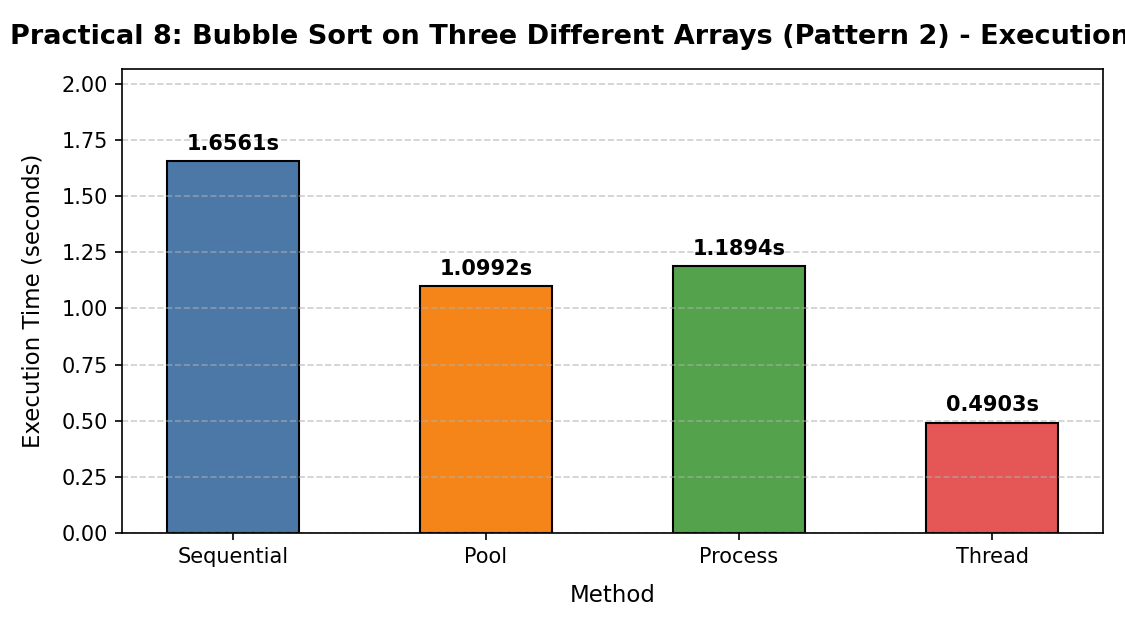

#### B. Speedup Comparison relative to Sequential
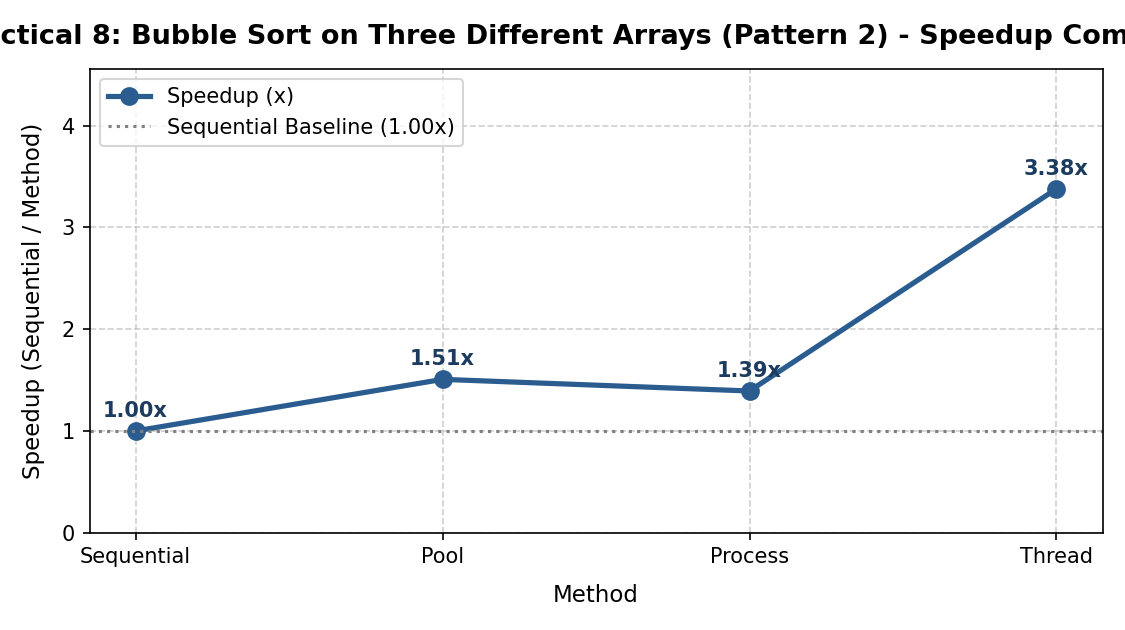
